Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [ ]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy
import json
from ipywidgets import interactive
import math

import matplotlib.animation
from IPython.display import HTML

import cvxpy as cp
import gurobipy as gp

from matplotlib.patches import Patch

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [83]:
plt.rcParams.update({'font.size': 15})

In [4]:
parameter_file = '/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144748/stable_model_parameters.json'
crop_repartition = np.array([[ 1.0, 1.0, 0.3 ], [0.0, 0.0, 0.3 ], [ 0.0, 0.0, 0.3 ], [ 0.0, 0.0, 0.4 ]])

In [5]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crop_repartition)

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_53428/3956881165.py:57: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


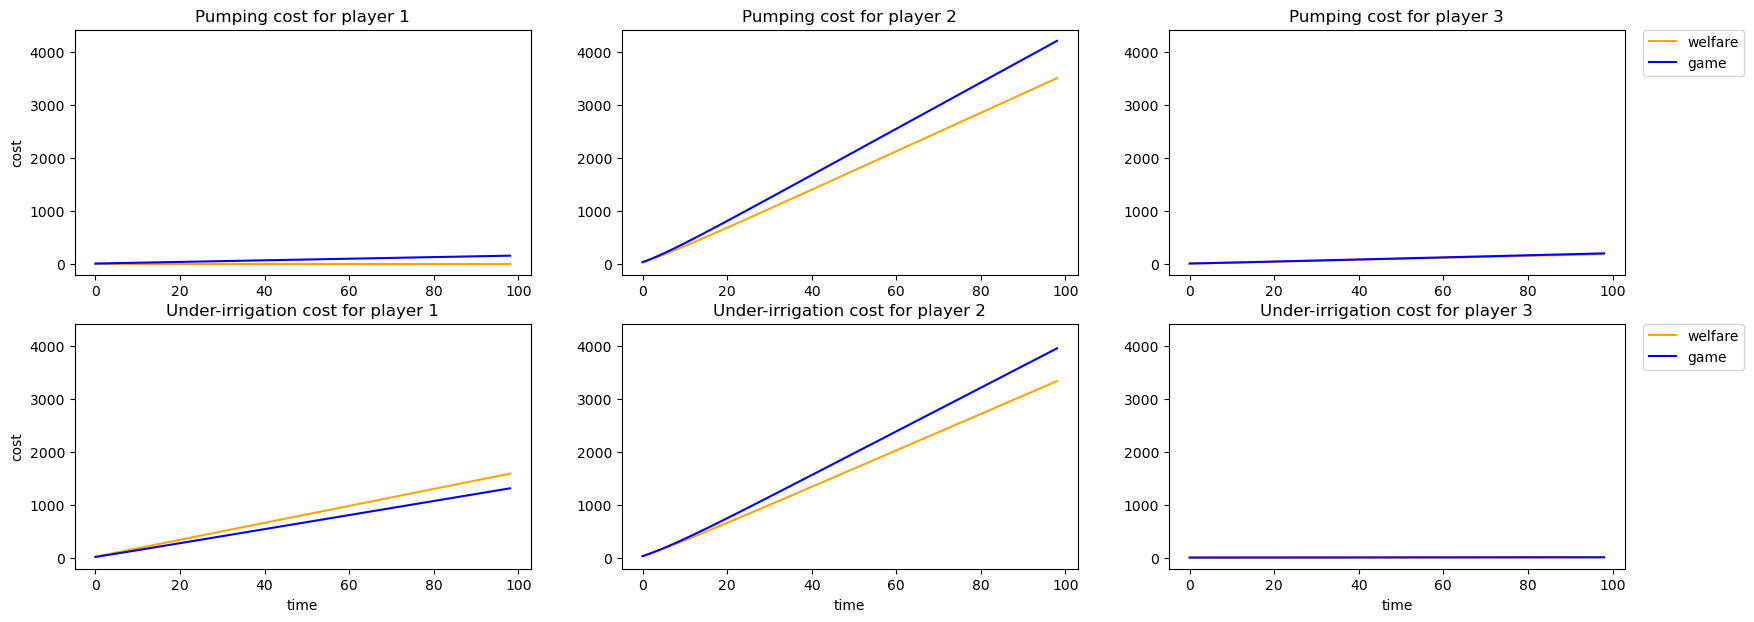

In [66]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144748/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144617/result_data.npz')

parameter_file = '/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144748/stable_model_parameters.json'
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, np.array([[1.0, 1.0, 0.3 ], [0.0, 0.0, 0.3], [0.0, 0.0, 0.3], [0.0, 0.0, 0.4]]))

def compute_cost(x: np.ndarray, u: np.ndarray, time: int = None) -> np.ndarray:
    """parameter u of shape [n_well, n_crops] contains negative values"""
    u = u.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops))
    ET = cost_model._get_water_requirement(time, 1)[:,:,0]
    Ry = cost_model._get_under_irrigation_weight(time, 1)
    pumping_cost = np.zeros((cost_model.n_agent, 1))
    under_irrigation_cost = np.zeros((cost_model.n_agent, 1))
    for v in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
        well_indices = np.arange(np.hstack(cost_model.n_well_per_command).sum(), dtype=int)[cost_model.well_to_agent==v]
        pumping_cost[v] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
            x[well_indices]).reshape(-1,1) * u[cost_model.well_to_agent==v,:].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = ET[v, :] + u[cost_model.well_to_agent==v,:].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost[v] = \
            under_irrigation.T @ sp.diags(Ry[v,:].flatten()) @ under_irrigation.T
    return pumping_cost, under_irrigation_cost


costs_game = np.hstack([- np.vstack(compute_cost(data_si['h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_si['inputs'][:,[t]]),
                                     t)) for t in range(99)])
costs_welfare = np.hstack([- np.vstack(compute_cost(data_wf['h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_wf['inputs'][:,[t]]),
                                     t)) for t in range(99)])


# Plot cost per player
fig = plt.figure(figsize=(15+5,7))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping cost for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-np.cumsum(costs_welfare[ii, :]), color="orange", label='welfare')
    ax.plot(-np.cumsum(costs_game[ii, :]), color="blue", label='game')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

for ii in range(3):
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ttl = f"Under-irrigation cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-np.cumsum(costs_welfare[ii+3, :]), color="orange", label='welfare')
    ax.plot(-np.cumsum(costs_game[ii+3, :]), color="blue", label='game')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_53428/2818549951.py:67: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_53428/2818549951.py:81: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


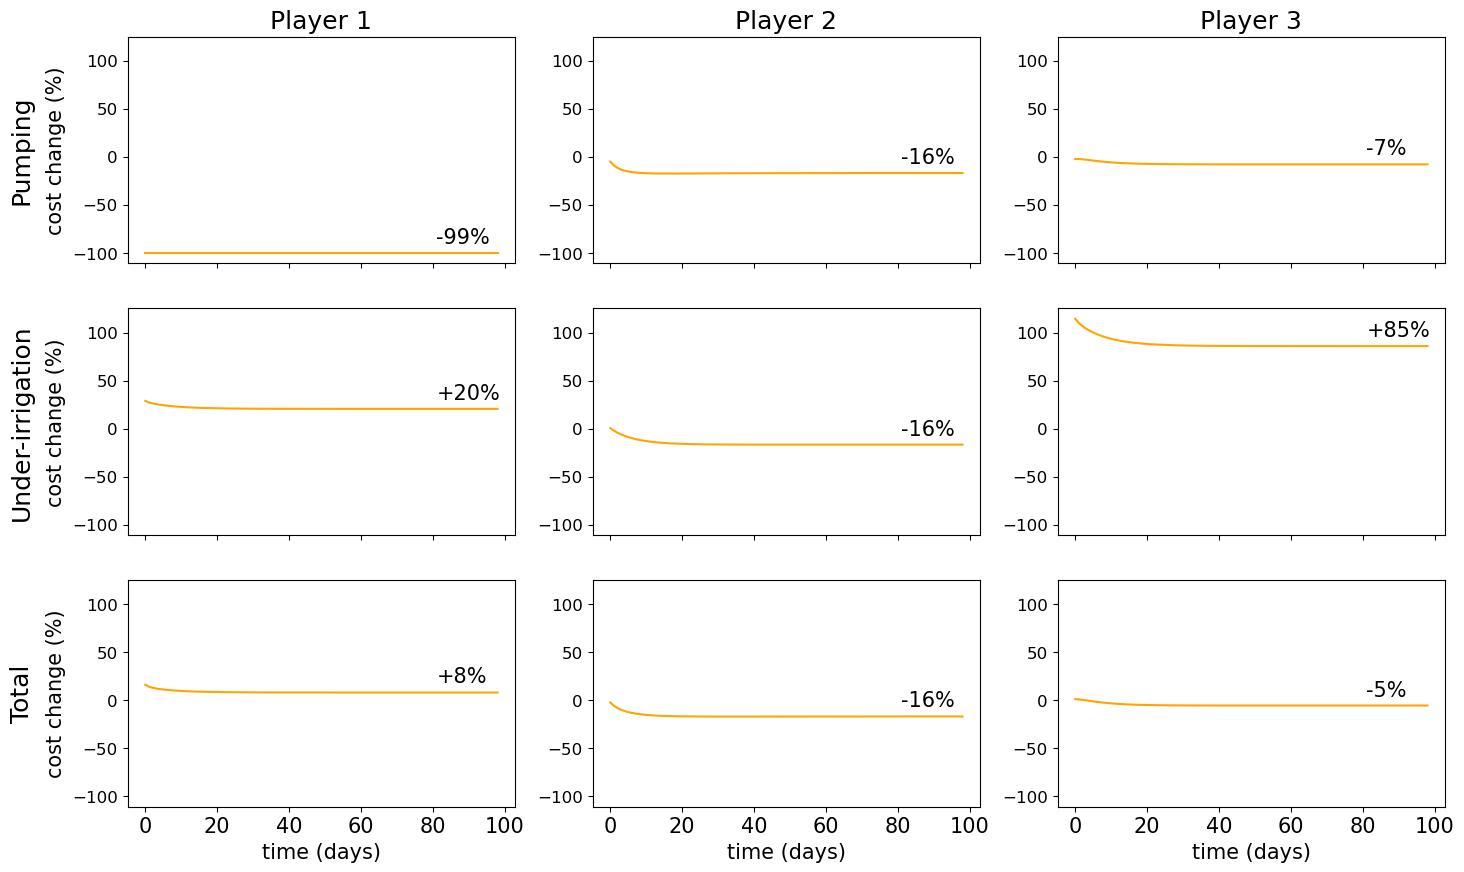

In [103]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144748/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144617/result_data.npz')

parameter_file = '/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144748/stable_model_parameters.json'
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, np.array([[1.0, 1.0, 0.3 ], [0.0, 0.0, 0.3], [0.0, 0.0, 0.3], [0.0, 0.0, 0.4]]))

def compute_cost(x: np.ndarray, u: np.ndarray, time: int = None) -> np.ndarray:
    """parameter u of shape [n_well, n_crops] contains negative values"""
    u = u.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops))
    ET = cost_model._get_water_requirement(time, 1)[:,:,0]
    Ry = cost_model._get_under_irrigation_weight(time, 1)
    pumping_cost = np.zeros((cost_model.n_agent, 1))
    under_irrigation_cost = np.zeros((cost_model.n_agent, 1))
    for v in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
        well_indices = np.arange(np.hstack(cost_model.n_well_per_command).sum(), dtype=int)[cost_model.well_to_agent==v]
        pumping_cost[v] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
            x[well_indices]).reshape(-1,1) * u[cost_model.well_to_agent==v,:].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = ET[v, :] + u[cost_model.well_to_agent==v,:].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost[v] = \
            under_irrigation.T @ sp.diags(Ry[v,:].flatten()) @ under_irrigation.T
    return pumping_cost, under_irrigation_cost


costs_game = np.hstack([- np.vstack(compute_cost(data_si['h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_si['inputs'][:,[t]]),
                                     t)) for t in range(99)])
costs_welfare = np.hstack([- np.vstack(compute_cost(data_wf['h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_wf['inputs'][:,[t]]),
                                     t)) for t in range(99)])

total_game_cost = costs_game.sum(axis=1) # np.kron([[1,1]], np.eye(3)) @ 

costs_augmentation_welfare = ((costs_welfare-costs_game)/costs_game)
total_cost_augmentation_welfare = ((np.kron([[1,1]], np.eye(3)) @ (costs_welfare))/((np.kron([[1,1]], np.eye(3)) @ costs_game))) - 1

# Plot cost per player
fig = plt.figure(figsize=(17,10))
ax = None
for ii in range(3):
    ax = fig.add_subplot(3, 3, ii+1, sharey=ax)
    ax.tick_params(axis='y', which='major', labelsize=12)
    ttl = f"Player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Pumping', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(costs_augmentation_welfare[ii, :]), color="orange", label='welfare')
    ax.text(costs_augmentation_welfare.shape[1]-18, 100*costs_augmentation_welfare[ii,-1]+10, f"{int(costs_augmentation_welfare[ii,-1]*100):+}%")
    ax.set_xticklabels([])

#ax=None
for ii in range(3):
    ax = fig.add_subplot(3, 3, 3+ii+1, sharey=ax)
    ax.tick_params(axis='y', which='major', labelsize=12)
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Under-irrigation', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(costs_augmentation_welfare[ii+3, :]), color="orange", label='welfare')
    ax.text(costs_augmentation_welfare.shape[1]-18, 100*costs_augmentation_welfare[ii+3,-1]+10, f"{int(costs_augmentation_welfare[ii+3,-1]*100):+}%")
    ax.set_xticklabels([])
fig.show()

#ax=None
for ii in range(3):
    ax = fig.add_subplot(3, 3, 6+ii+1, sharey=ax)
    ax.tick_params(axis='y', which='major', labelsize=12)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Total', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(total_cost_augmentation_welfare[ii, :]), color="orange", label='welfare')
    ax.text(total_cost_augmentation_welfare.shape[1]-18, 100*total_cost_augmentation_welfare[ii,-1]+10, f"{int(total_cost_augmentation_welfare[ii,-1]*100):+}%")
fig.show()

In [10]:
water_req = cost_model._get_water_requirement(0, 100)
rain = cost_model._get_available_water(0, 100)

n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

player_pumping_g = well_to_agent @ data_si['q_rates']
player_pumping_w = well_to_agent @ data_wf['q_rates']

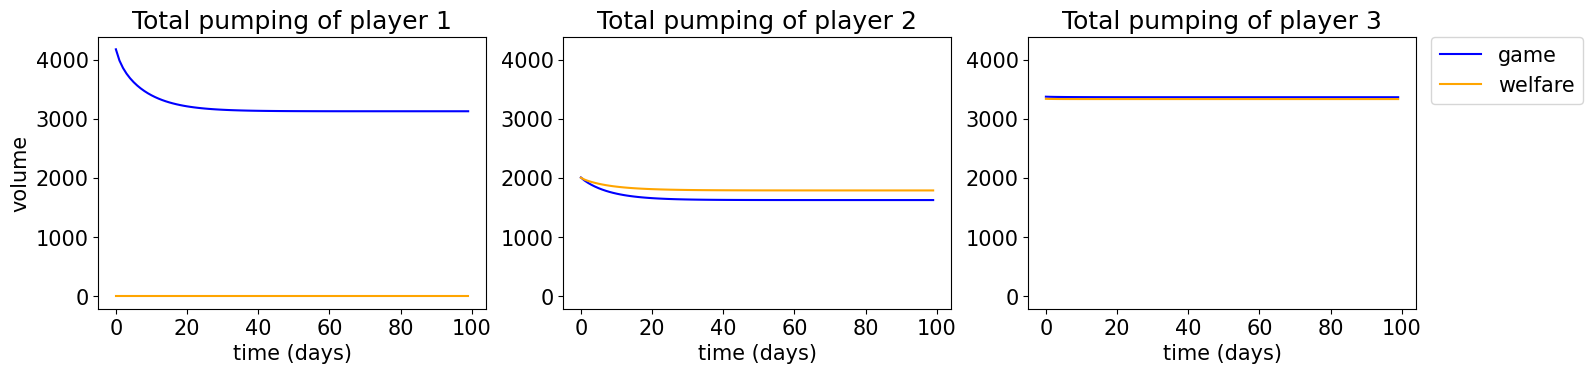

In [87]:
fig = plt.figure(figsize=(17,12))
ax = None
for ii in range(3):
    ax = fig.add_subplot(3, 3, ii+1, sharey=ax)
    ttl = f"Total pumping of player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("volume")
    #ax.plot((water_req+rain)[ii, :, :].sum(axis=0), color="black", linestyle="--", label='requirement')
    #ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.plot(-player_pumping_g[ii, :] + rain[ii,:,:].sum(axis=0), "b-", label='game')
    ax.plot(-player_pumping_w[ii, :] + rain[ii,:,:].sum(axis=0), "orange", label='welfare')
    #ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [ ]:
colors = ['blue', 'orange']
names = ['game', 'welfare']

water_spared = []
yield_loss = []
for d, (data, player_pumping) in enumerate(zip([data_si, data_wf], [player_pumping_g, player_pumping_w])):
    crop_irrigation = -(sp.block_diag(cost_model.input_to_crop_irrigation_v) @ data['inputs']).reshape(3,4,-1)
    yield_proportion = np.where(water_req+rain==0, 0, (1-(crop_irrigation+rain)/(water_req+rain))*cost_model._get_yield_coefficient(0,365))

    std = np.array([np.std(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)
    mean = np.array([np.mean(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)

    water_spared.append((water_req.sum(axis=1).sum(axis=1) + player_pumping.sum(axis=1))/water_req.sum(axis=1).sum(axis=1))
    yield_loss.append((mean*(crop_repartition / crop_repartition.sum(axis=0)).T).sum(axis=1))
water_spared = np.vstack(water_spared)
yield_loss = np.vstack(yield_loss)


fig = plt.figure(figsize=(15,5))
ax = None 
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("%")
    for d in range(3):
        rects = ax.bar(np.linspace(0,2,3)[d], 100*water_spared[d,ii], width=0.35, color=colors[d], label='water savings')
        rects = ax.bar(np.linspace(0,2,3)[d]+0.40, 100*yield_loss[d,ii], width=0.35, color=colors[d], hatch='///', label='yield loss')
        for bar in rects:
            bar._hatch_color = (1.0, 1.0, 1.0, 1.0)
    ax.set_xticks(np.linspace(0,2,3)+0.2, names)
    for i, (w,y) in enumerate(zip(water_spared[:,ii], yield_loss[:,ii])):
        plt.text(i-0.2, 100*w+1, str(int(100*w))+'%')
        plt.text(i+0.25, 100*y+1, str(int(100*y))+'%')
    ax.set_ybound([0,100])
ax.legend(handles=[Patch(facecolor='grey', label='water savings'),
                   Patch(facecolor='grey', hatch='///', label='yield loss')],
          bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)